# Lesson 8: Logistic regression on Titanic data

Predict passenger survival and compare a logistic model written with NumPy against scikit-learn. Run the cells from this folder with pandas, NumPy, SciPy, Matplotlib, and scikit-learn installed. Lesson 6 covers the exploratory plots.

**Data:** [Titanic: Machine Learning from Disaster](https://www.kaggle.com/competitions/titanic/data). Download the labeled `train.csv`, rename it to `data_tms.csv`, and place it in this lesson folder.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.special import expit
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, log_loss, ConfusionMatrixDisplay
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

df = pd.read_csv("data_tms.csv")
df["FamilySize"] = 1 + df["SibSp"] + df["Parch"]
X_train, X_test, y_train, y_test = train_test_split(
    df.drop(columns="Survived"), df["Survived"],
    test_size=0.2, random_state=42, stratify=df["Survived"],
)
pd.DataFrame({"Rows": [len(X_train), len(X_test)],
              "Survival rate": [y_train.mean(), y_test.mean()]},
             index=["Train", "Test"])

,Rows,Survival rate
Train,712,0.383427
Test,179,0.385475


## Preprocess the features

Fit the imputers, scaler, and category encoder on the training split. One-hot encoding treats embarkation ports as categories without imposing an order. A test category absent from training gets an all-zero encoding.

In [2]:
def make_preprocessor(numeric, categorical):
    return ColumnTransformer([
        ("numeric", make_pipeline(SimpleImputer(strategy="median"), StandardScaler()), numeric),
        ("categorical", make_pipeline(
            SimpleImputer(strategy="most_frequent"),
            OneHotEncoder(handle_unknown="ignore"),
        ), categorical),
    ])

numeric = ["Age", "FamilySize"]
categorical = ["Pclass", "Sex", "Embarked"]
preprocessor = make_preprocessor(numeric, categorical)
train = preprocessor.fit_transform(X_train)
test = preprocessor.transform(X_test)

## Fit logistic regression

The sigmoid turns a linear score into a survival probability. Each gradient step adjusts the weights and intercept to reduce binary log loss. The scikit-learn comparison uses the same features and disables regularization.

In [3]:
class MyLogisticRegression:
    def fit(self, X, y, learning_rate=0.1, iterations=3000):
        self.weights = np.zeros(X.shape[1])
        self.intercept = 0.0
        y = np.asarray(y)
        for _ in range(iterations):
            errors = self.predict_proba(X) - y
            self.weights -= learning_rate * (X.T @ errors) / len(y)
            self.intercept -= learning_rate * errors.mean()
        return self

    def predict_proba(self, X):
        return expit(X @ self.weights + self.intercept)

    def predict(self, X):
        return (self.predict_proba(X) >= 0.5).astype(int)

custom = MyLogisticRegression().fit(train, y_train)
reference = LogisticRegression(penalty=None, max_iter=1000).fit(train, y_train)

~/Documents/Codex/2026-11-05/new-chat/work/lesson5-venv/lib/python3.11/site-packages/sklearn/linear_model/_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(


## Compare training and test results

Use the majority class as a baseline. The age-only model tests what a single feature can explain. The identifier-heavy model adds names, tickets, and cabins to see whether extra detail improves training accuracy without a similar gain on the test split. A gap on this split illustrates the risk of overfitting.

In [4]:
def evaluate(name, train_prob, test_prob):
    return {
        "Model": name,
        "Train accuracy": accuracy_score(y_train, train_prob >= 0.5),
        "Test accuracy": accuracy_score(y_test, test_prob >= 0.5),
        "Test log loss": log_loss(y_test, test_prob),
    }

majority = DummyClassifier(strategy="most_frequent").fit(train, y_train)
age_only = make_pipeline(
    SimpleImputer(strategy="median"), StandardScaler(), LogisticRegression()
).fit(X_train[["Age"]], y_train)
identifiers = make_pipeline(
    make_preprocessor(numeric, categorical + ["Name", "Ticket", "Cabin"]),
    LogisticRegression(C=100, max_iter=2000),
).fit(X_train, y_train)

results = [
    evaluate("Majority class", majority.predict_proba(train)[:, 1], majority.predict_proba(test)[:, 1]),
    evaluate("Age only", age_only.predict_proba(X_train[["Age"]])[:, 1],
             age_only.predict_proba(X_test[["Age"]])[:, 1]),
    evaluate("NumPy logistic regression", custom.predict_proba(train), custom.predict_proba(test)),
    evaluate("scikit-learn logistic regression", reference.predict_proba(train)[:, 1],
             reference.predict_proba(test)[:, 1]),
    evaluate("With passenger identifiers", identifiers.predict_proba(X_train)[:, 1],
             identifiers.predict_proba(X_test)[:, 1]),
]
pd.DataFrame(results).set_index("Model").round(3)

,Train accuracy,Test accuracy,Test log loss
Model,,,
Majority class,0.617,0.615,13.894
Age only,0.617,0.615,0.666
NumPy logistic regression,0.808,0.793,0.466
scikit-learn logistic regression,0.808,0.793,0.466
With passenger identifiers,1.000,0.804,0.554


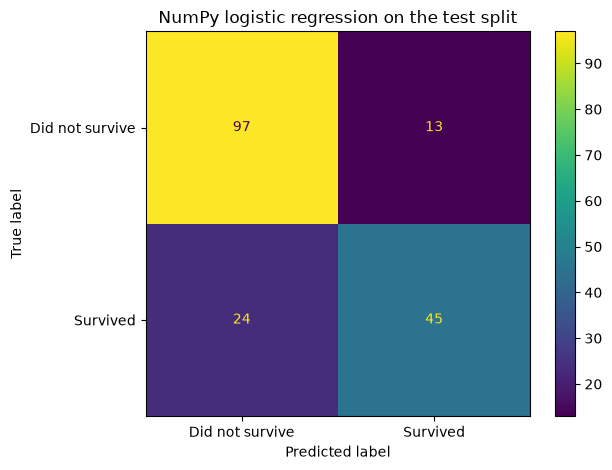

In [5]:
ConfusionMatrixDisplay.from_predictions(
    y_test, custom.predict(test), display_labels=["Did not survive", "Survived"]
)
plt.title("NumPy logistic regression on the test split")
plt.tight_layout()
plt.show()